# Instalación e importación de librerías

In [1]:
!pip install -q polars statsforecast optuna shap plotly

import os
import zipfile
import warnings
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from scipy.stats import norm
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive
import lightgbm as lgb
import xgboost as xgb
import optuna
import shap

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Fase 1 — Data Acquisition & Validation

In [2]:
ZIP_PATH = '/content/store-sales-time-series-forecasting.zip'
RAW_DIR = '/content/raw_data'

os.makedirs(RAW_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(RAW_DIR)

train = pl.read_csv(f'{RAW_DIR}/train.csv', try_parse_dates=True)
stores = pl.read_csv(f'{RAW_DIR}/stores.csv')
transactions = pl.read_csv(f'{RAW_DIR}/transactions.csv', try_parse_dates=True)
oil = pl.read_csv(f'{RAW_DIR}/oil.csv', try_parse_dates=True)
holidays = pl.read_csv(f'{RAW_DIR}/holidays_events.csv', try_parse_dates=True)

tablas = {'train': train, 'stores': stores, 'transactions': transactions, 'oil': oil, 'holidays': holidays}
validacion = []
for nombre, df_t in tablas.items():
    nulos = sum(df_t.null_count().row(0))
    duplicados = df_t.is_duplicated().sum()
    validacion.append({'Tabla': nombre, 'Filas': df_t.height, 'Columnas': df_t.width, 'Nulos': nulos, 'Duplicados': duplicados})

print("=== AUDITORÍA DE CALIDAD DE DATOS ===")
print(pd.DataFrame(validacion).to_string(index=False))

perishable_families = ['PRODUCE', 'DAIRY', 'DELI', 'MEATS', 'POULTRY', 'SEAFOOD', 'BREAD/BAKERY']

oil_clean = (
    train.select('date').unique().sort('date')
    .join(oil, on='date', how='left')
    .with_columns(pl.col('dcoilwtico').forward_fill().backward_fill().alias('oil_price'))
    .select(['date', 'oil_price'])
)

holidays_clean = (
    holidays.filter(pl.col('transferred') == False)
    .group_by('date')
    .agg([
        pl.first('type').alias('holiday_type'),
        pl.first('locale').alias('holiday_locale')
    ])
)

df_analytical = (
    train
    .with_columns([
        pl.col('sales').clip(lower_bound=0.0).cast(pl.Float32),
        pl.col('onpromotion').fill_null(0).cast(pl.Int32),
        pl.col('store_nbr').cast(pl.Int32),
        pl.col('family').is_in(perishable_families).cast(pl.Int8).alias('is_perishable')
    ])
    .join(stores.rename({'type': 'store_type'}), on='store_nbr', how='left')
    .join(transactions, on=['date', 'store_nbr'], how='left')
    .join(oil_clean, on='date', how='left')
    .join(holidays_clean, on='date', how='left')
    .with_columns([
        pl.col('transactions').fill_null(0).cast(pl.Int32),
        pl.col('holiday_type').is_not_null().cast(pl.Int8).alias('is_holiday'),
        pl.col('holiday_type').fill_null('Normal'),
        pl.col('holiday_locale').fill_null('None')
    ])
    .drop('id')
    .sort(['store_nbr', 'family', 'date'])
)

df_analytical.write_parquet('/content/analytical_dataset.parquet')

print("\n=== DATASET ANALÍTICO CONSOLIDADO ===")
print(f"Dimensiones: {df_analytical.shape}")
print(f"Rango temporal: {df_analytical['date'].min()} -> {df_analytical['date'].max()}")
print(f"Nulos residuales: {sum(df_analytical.null_count().row(0))}")
print(df_analytical.head(5))

=== AUDITORÍA DE CALIDAD DE DATOS ===
       Tabla   Filas  Columnas  Nulos  Duplicados
       train 3000888         6      0           0
      stores      54         5      0           0
transactions   83488         3      0           0
         oil    1218         2     43           0
    holidays     350         6      0           0

=== DATASET ANALÍTICO CONSOLIDADO ===
Dimensiones: (3000888, 15)
Rango temporal: 2013-01-01 -> 2017-08-15
Nulos residuales: 0
shape: (5, 15)
┌────────────┬───────────┬────────────┬───────┬───┬───────────┬────────────┬───────────┬───────────┐
│ date       ┆ store_nbr ┆ family     ┆ sales ┆ … ┆ oil_price ┆ holiday_ty ┆ holiday_l ┆ is_holida │
│ ---        ┆ ---       ┆ ---        ┆ ---   ┆   ┆ ---       ┆ pe         ┆ ocale     ┆ y         │
│ date       ┆ i32       ┆ str        ┆ f32   ┆   ┆ f64       ┆ ---        ┆ ---       ┆ ---       │
│            ┆           ┆            ┆       ┆   ┆           ┆ str        ┆ str       ┆ i8        │
╞════════════╪═

# Fase 2 — Exploratory Data Analysis

In [6]:
df_an = pl.read_parquet('/content/analytical_dataset.parquet')

# Anomalías (Z-Score)
df_diario = (
    df_an.group_by('date').agg(pl.col('sales').sum().alias('ventas'))
    .sort('date')
    .with_columns([
        pl.col('ventas').rolling_mean(28).alias('ma28'),
        pl.col('ventas').rolling_std(28).alias('std28')
    ])
    .with_columns(((pl.col('ventas') - pl.col('ma28')) / (pl.col('std28') + 1e-8)).alias('z'))
    .with_columns((pl.col('z').abs() > 3.0).fill_null(False).alias('anomalia'))
).to_pandas()

# Estacionalidad y test de promociones
df_est = (
    df_an.with_columns([pl.col('date').dt.weekday().alias('dia'), (pl.col('onpromotion') > 0).alias('promo')])
    .group_by(['dia', 'promo']).agg(pl.col('sales').mean().alias('venta_prom'))
    .sort(['dia', 'promo'])
).to_pandas()

m_promo = df_an.filter(pl.col('onpromotion') > 0)['sales'].sample(50000, seed=42).to_numpy()
m_no_promo = df_an.filter(pl.col('onpromotion') == 0)['sales'].sample(50000, seed=42).to_numpy()
_, p_val = stats.mannwhitneyu(m_promo, m_no_promo, alternative='greater')

# Intermitencia (ADI vs CV2)
df_inter = (
    df_an.group_by('family').agg([
        pl.col('sales').sum().alias('ventas'),
        pl.col('sales').mean().alias('media'),
        pl.col('sales').std().alias('std'),
        pl.len().alias('n'),
        (pl.col('sales') > 0).sum().alias('n_pos')
    ])
    .with_columns([
        (pl.col('n') / (pl.col('n_pos') + 1e-8)).round(2).alias('ADI'),
        ((pl.col('std') / (pl.col('media') + 1e-8)) ** 2).round(2).alias('CV2')
    ])
    .with_columns(
        pl.when((pl.col('ADI') < 1.32) & (pl.col('CV2') < 0.49)).then(pl.lit('Smooth'))
        .when((pl.col('ADI') >= 1.32) & (pl.col('CV2') < 0.49)).then(pl.lit('Intermittent'))
        .when((pl.col('ADI') < 1.32) & (pl.col('CV2') >= 0.49)).then(pl.lit('Erratic'))
        .otherwise(pl.lit('Lumpy')).alias('perfil')
    )
    .sort('ventas', descending=True)
).to_pandas()

print(f"Anomalías: {df_diario['anomalia'].sum()} días | p-value promos: {p_val:.2e}")
print(df_inter[['family', 'ADI', 'CV2', 'perfil']].head(8).to_string(index=False))

# Gráficos
fig = make_subplots(rows=2, cols=2, subplot_titles=('Tendencia y Anomalías', 'Ventas por Día y Promo', 'Matriz ADI vs CV²', 'Top 15 Tiendas'))

anom = df_diario[df_diario['anomalia']]
fig.add_trace(go.Scatter(x=df_diario['date'], y=df_diario['ventas'], name='Ventas', line=dict(width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=anom['date'], y=anom['ventas'], mode='markers', name='Anomalías', marker=dict(color='red', size=5)), row=1, col=1)

for flag, lbl in [(True, 'Con Promo'), (False, 'Sin Promo')]:
    sub = df_est[df_est['promo'] == flag]
    fig.add_trace(go.Bar(x=sub['dia'], y=sub['venta_prom'], name=lbl), row=1, col=2)

fig.add_trace(go.Scatter(x=df_inter['ADI'], y=df_inter['CV2'], mode='markers+text', text=df_inter['family'].str[:6], textposition='top center', name='Familias'), row=2, col=1)
fig.add_vline(x=1.32, line_dash='dash', row=2, col=1)
fig.add_hline(y=0.49, line_dash='dash', row=2, col=1)

top_t = df_an.group_by('store_nbr').agg(pl.col('sales').sum()).sort('sales', descending=True).head(15).to_pandas()
fig.add_trace(go.Bar(x=top_t['store_nbr'].astype(str), y=top_t['sales'], name='Tiendas'), row=2, col=2)

fig.update_layout(height=650, title_text='EDA — Corporación Favorita', template='plotly_white')
fig.show()

Anomalías: 10 días | p-value promos: 0.00e+00
      family  ADI  CV2  perfil
   GROCERY I 1.09 0.58 Erratic
   BEVERAGES 1.09 0.94 Erratic
     PRODUCE 1.40 2.63   Lumpy
    CLEANING 1.09 0.47  Smooth
       DAIRY 1.09 0.90 Erratic
BREAD/BAKERY 1.09 0.63 Erratic
     POULTRY 1.09 1.31 Erratic
       MEATS 1.09 1.78 Erratic


# Fase 3 — Feature Engineering

In [7]:
df_an = pl.read_parquet('/content/analytical_dataset.parquet')

df_feat = (
    df_an.sort(['store_nbr', 'family', 'date'])
    .with_columns([
        # Calendario y estacionalidad
        pl.col('date').dt.weekday().cast(pl.Int8).alias('day_of_week'),
        pl.col('date').dt.day().cast(pl.Int8).alias('day_of_month'),
        pl.col('date').dt.month().cast(pl.Int8).alias('month'),
        (pl.col('date').dt.weekday() >= 6).cast(pl.Int8).alias('is_weekend'),
        pl.col('date').dt.day().is_in([15, 30, 31]).cast(pl.Int8).alias('is_payday'),
        (2 * np.pi * pl.col('date').dt.ordinal_day() / 365.25).sin().cast(pl.Float32).alias('sin_year'),
        (2 * np.pi * pl.col('date').dt.ordinal_day() / 365.25).cos().cast(pl.Float32).alias('cos_year'),

        # Lags (sin leakage)
        pl.col('sales').shift(1).over(['store_nbr', 'family']).alias('lag_1'),
        pl.col('sales').shift(7).over(['store_nbr', 'family']).alias('lag_7'),
        pl.col('sales').shift(14).over(['store_nbr', 'family']).alias('lag_14'),
        pl.col('sales').shift(28).over(['store_nbr', 'family']).alias('lag_28'),

        # Rolling stats y promociones
        pl.col('sales').shift(1).rolling_mean(7).over(['store_nbr', 'family']).alias('roll_mean_7'),
        pl.col('sales').shift(1).rolling_mean(28).over(['store_nbr', 'family']).alias('roll_mean_28'),
        pl.col('sales').shift(1).rolling_std(28).over(['store_nbr', 'family']).alias('roll_std_28'),
        pl.col('onpromotion').shift(1).rolling_mean(7).over(['store_nbr', 'family']).alias('promo_freq_7')
    ])
    .with_columns([
        # Tendencia
        ((pl.col('lag_1') - pl.col('lag_7')) / (pl.col('lag_7') + 1.0)).alias('weekly_pct_change'),
        (pl.col('roll_mean_7') / (pl.col('roll_mean_28') + 1.0)).alias('trend_ratio_7_28')
    ])
    .filter(pl.col('date') >= pl.date(2017, 1, 1))
    .drop(['city', 'state', 'cluster', 'transactions', 'holiday_type', 'holiday_locale'])
)

df_feat.write_parquet('/content/features_2017.parquet')
print(f"Dataset listo: {df_feat.shape} | Rango: {df_feat['date'].min()} -> {df_feat['date'].max()}")

Dataset listo: (404514, 26) | Rango: 2017-01-01 -> 2017-08-15


# Fase 4 — Model Development

In [8]:
df = pl.read_parquet('/content/features_2017.parquet').to_pandas()
df['family_cat'] = df['family'].astype('category')
df['store_type_cat'] = df['store_type'].astype('category')
df['unique_id'] = df['store_nbr'].astype(str) + '_' + df['family']

features = [
    'store_nbr', 'family_cat', 'store_type_cat', 'onpromotion', 'is_perishable',
    'oil_price', 'is_holiday', 'day_of_week', 'day_of_month', 'month',
    'is_weekend', 'is_payday', 'sin_year', 'cos_year',
    'lag_1', 'lag_7', 'lag_14', 'lag_28',
    'roll_mean_7', 'roll_mean_28', 'roll_std_28', 'promo_freq_7',
    'weekly_pct_change', 'trend_ratio_7_28'
]

# Métricas
def calc_metrics(y_true, y_pred, mase_denom):
    y_pred = np.clip(y_pred, 0, None)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    wape = np.sum(np.abs(y_true - y_pred)) / (np.sum(y_true) + 1e-8)
    mase = mae / (mase_denom + 1e-8)
    bias = np.sum(y_pred - y_true) / (np.sum(y_true) + 1e-8)
    return {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'WAPE (%)': round(wape * 100, 2), 'MASE': round(mase, 3), 'Bias (%)': round(bias * 100, 2)}

# Split temporal (Holdout 15 días: 2017-08-01 a 2017-08-15)
cutoff = pd.Timestamp('2017-08-01')
train_df = df[df['date'] < cutoff].copy()
test_df = df[df['date'] >= cutoff].copy()

# Denominador MASE (error naive in-sample)
mase_denom = train_df.groupby('unique_id')['sales'].diff(1).abs().mean()
y_test = test_df['sales'].values

# 1 & 2. Naive y Seasonal Naive (StatsForecast)
sf_train = train_df[['unique_id', 'date', 'sales']].rename(columns={'date': 'ds', 'sales': 'y'})
sf = StatsForecast(models=[Naive(), SeasonalNaive(season_length=7)], freq='D', n_jobs=-1)
sf_preds = sf.forecast(df=sf_train, h=15).reset_index()
test_sf = test_df[['unique_id', 'date']].merge(sf_preds, left_on=['unique_id', 'date'], right_on=['unique_id', 'ds'], how='left')

# 3. SARIMAX (Top-Down por familia)
shares = train_df[train_df['date'] >= '2017-07-01'].groupby(['family', 'store_nbr'])['sales'].sum()
shares = (shares / shares.groupby('family').transform('sum')).fillna(0).reset_index().rename(columns={'sales': 'share'})

sarimax_preds = []
for fam, grp in train_df.groupby('family'):
    ts = grp.groupby('date')['sales'].sum().asfreq('D').fillna(0)
    mod = SARIMAX(ts, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7), enforce_stationarity=False, enforce_invertibility=False)
    fc = mod.fit(disp=False).forecast(steps=15)
    sarimax_preds.append(pd.DataFrame({'family': fam, 'date': fc.index, 'fam_pred': fc.values}))

df_sarimax = test_df[['store_nbr', 'family', 'date']].merge(pd.concat(sarimax_preds), on=['family', 'date']).merge(shares, on=['family', 'store_nbr'])
df_sarimax['sarimax_pred'] = df_sarimax['fam_pred'] * df_sarimax['share']

# 4. Backtesting temporal (2 folds de 15 días) + Entrenamiento XGBoost y LightGBM
folds = [('2017-07-02', '2017-07-17'), ('2017-07-17', '2017-08-01')]
cv_wape = {'XGBoost': [], 'LightGBM': []}

for val_start, val_end in folds:
    tr = train_df[train_df['date'] < val_start]
    va = train_df[(train_df['date'] >= val_start) & (train_df['date'] < val_end)]

    m_xgb = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, enable_categorical=True, tree_method='hist', random_state=42)
    m_xgb.fit(tr[features], tr['sales'])
    cv_wape['XGBoost'].append(np.sum(np.abs(va['sales'] - np.clip(m_xgb.predict(va[features]), 0, None))) / va['sales'].sum())

    m_lgb = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
    m_lgb.fit(tr[features], tr['sales'])
    cv_wape['LightGBM'].append(np.sum(np.abs(va['sales'] - np.clip(m_lgb.predict(va[features]), 0, None))) / va['sales'].sum())

print(f"Backtesting WAPE promedio -> XGBoost: {np.mean(cv_wape['XGBoost'])*100:.2f}% | LightGBM: {np.mean(cv_wape['LightGBM'])*100:.2f}%\n")

# Entrenamiento final en todo train_df
model_xgb = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, enable_categorical=True, tree_method='hist', random_state=42)
model_xgb.fit(train_df[features], train_df['sales'])
pred_xgb = model_xgb.predict(test_df[features])

model_lgb = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
model_lgb.fit(train_df[features], train_df['sales'])
pred_lgb = model_lgb.predict(test_df[features])

# Tabla comparativa en Test
resultados = []
for nombre, preds in [
    ('Naive', test_sf['Naive'].values),
    ('Seasonal Naive (7d)', test_sf['SeasonalNaive'].values),
    ('SARIMAX', df_sarimax['sarimax_pred'].values),
    ('XGBoost', pred_xgb),
    ('LightGBM', pred_lgb)
]:
    row = {'Modelo': nombre}
    row.update(calc_metrics(y_test, preds, mase_denom))
    resultados.append(row)

df_resultados = pd.DataFrame(resultados).sort_values('WAPE (%)')
print("=== COMPARACIÓN DE MODELOS (TEST 15 DÍAS) ===")
print(df_resultados.to_string(index=False))

Backtesting WAPE promedio -> XGBoost: 12.53% | LightGBM: 12.02%

=== COMPARACIÓN DE MODELOS (TEST 15 DÍAS) ===
             Modelo    MAE   RMSE  WAPE (%)  MASE  Bias (%)
           LightGBM  71.21 241.06 15.310000 0.526      6.66
            XGBoost  73.66 245.55 15.840000 0.544      7.51
            SARIMAX  94.37 301.74 20.290000 0.697      2.35
Seasonal Naive (7d)  98.69 357.25 21.219999 0.729      2.11
              Naive 114.18 363.87 24.549999 0.843      6.87


# Fase 5 — Hyperparameter Optimization

In [9]:
# Optuna sobre validación temporal (estabilidad entre folds)
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 800, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 31, 127),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1
    }

    fold_wapes = []
    for val_start, val_end in folds:
        tr = train_df[train_df['date'] < val_start]
        va = train_df[(train_df['date'] >= val_start) & (train_df['date'] < val_end)]

        m = lgb.LGBMRegressor(**params)
        m.fit(tr[features], tr['sales'])
        preds = np.clip(m.predict(va[features]), 0, None)
        fold_wapes.append(np.sum(np.abs(va['sales'] - preds)) / va['sales'].sum())

    trial.set_user_attr('fold_std', float(np.std(fold_wapes)))
    return float(np.mean(fold_wapes))

study = optuna.create_study(direction='minimize', study_name='lgbm_retail_tuning')
study.optimize(objective, n_trials=20)

# Registro de experimentos y estabilidad
trials_df = study.trials_dataframe()[['number', 'value', 'user_attrs_fold_std', 'params_learning_rate', 'params_num_leaves', 'params_n_estimators']]
trials_df.columns = ['Trial', 'CV_WAPE', 'Fold_Std', 'LR', 'Leaves', 'Trees']
trials_df['CV_WAPE (%)'] = (trials_df['CV_WAPE'] * 100).round(3)
trials_df['Fold_Std (%)'] = (trials_df['Fold_Std'] * 100).round(3)

print("=== TOP 5 CONFIGURACIONES OPTUNA ===")
print(trials_df.sort_values('CV_WAPE').head(5)[['Trial', 'CV_WAPE (%)', 'Fold_Std (%)', 'LR', 'Leaves', 'Trees']].to_string(index=False))

# Entrenamiento modelo optimizado y comparación en Test
best_params = {**study.best_params, 'random_state': 42, 'verbose': -1, 'n_jobs': -1}
model_lgb_opt = lgb.LGBMRegressor(**best_params)
model_lgb_opt.fit(train_df[features], train_df['sales'])
pred_lgb_opt = np.clip(model_lgb_opt.predict(test_df[features]), 0, None)

opt_row = {'Modelo': 'LightGBM (Optuna)'}
opt_row.update(calc_metrics(y_test, pred_lgb_opt, mase_denom))
df_resultados = pd.concat([df_resultados, pd.DataFrame([opt_row])], ignore_index=True).sort_values('WAPE (%)')

print("\n=== BENCHMARK ACTUALIZADO (TEST) ===")
print(df_resultados.to_string(index=False))

=== TOP 5 CONFIGURACIONES OPTUNA ===
 Trial  CV_WAPE (%)  Fold_Std (%)       LR  Leaves  Trees
    17       11.813         0.146 0.034658      58    500
    11       11.836         0.139 0.022326      75    500
     6       11.870         0.127 0.020942      37    500
    15       11.881         0.098 0.033301      38    600
    16       11.891         0.009 0.026445     121    600

=== BENCHMARK ACTUALIZADO (TEST) ===
             Modelo    MAE   RMSE  WAPE (%)  MASE  Bias (%)
  LightGBM (Optuna)  69.50 238.19 14.940000 0.513      6.19
           LightGBM  71.21 241.06 15.310000 0.526      6.66
            XGBoost  73.66 245.55 15.840000 0.544      7.51
            SARIMAX  94.37 301.74 20.290000 0.697      2.35
Seasonal Naive (7d)  98.69 357.25 21.219999 0.729      2.11
              Naive 114.18 363.87 24.549999 0.843      6.87


# Fase 6 — Probabilistic Forecasting

In [10]:
# Función Pinball Loss
def pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return np.mean(np.maximum(q * err, (q - 1) * err))

# Entrenamiento de modelos cuantílicos (P10, P50, P90)
quantiles = {'P10': 0.10, 'P50': 0.50, 'P90': 0.90}
q_preds = {}

for name, q in quantiles.items():
    m_q = lgb.LGBMRegressor(**best_params, objective='quantile', alpha=q)
    m_q.fit(train_df[features], train_df['sales'])
    q_preds[name] = np.clip(m_q.predict(test_df[features]), 0, None)

# Asegurar coherencia entre cuantiles (P10 <= P50 <= P90)
test_df['P10'] = np.minimum(q_preds['P10'], q_preds['P50'])
test_df['P50'] = q_preds['P50']
test_df['P90'] = np.maximum(q_preds['P90'], q_preds['P50'])

# Evaluación de cobertura (objetivo teórico: 80% entre P10 y P90) y Pinball Loss
cobertura = np.mean((y_test >= test_df['P10']) & (y_test <= test_df['P90'])) * 100
pb_10 = pinball_loss(y_test, test_df['P10'], 0.10)
pb_50 = pinball_loss(y_test, test_df['P50'], 0.50)
pb_90 = pinball_loss(y_test, test_df['P90'], 0.90)

print(f"Cobertura Intervalo [P10 - P90]: {cobertura:.2f}% (Teórico: 80.0%)")
print(f"Pinball Loss -> P10: {pb_10:.2f} | P50: {pb_50:.2f} | P90: {pb_90:.2f}\n")

# Análisis de errores y cobertura por familia de producto (Top 10 por ventas)
err_familia = (
    test_df.groupby('family', observed=True)
    .apply(lambda g: pd.Series({
        'Ventas_Reales': g['sales'].sum(),
        'WAPE (%)': np.sum(np.abs(g['sales'] - g['P50'])) / (g['sales'].sum() + 1e-8) * 100,
        'Cobertura (%)': np.mean((g['sales'] >= g['P10']) & (g['sales'] <= g['P90'])) * 100,
        'Ancho_Banda_Prom': np.mean(g['P90'] - g['P10'])
    }), include_groups=False)
    .sort_values('Ventas_Reales', ascending=False)
    .round(2)
)

print("=== ERROR Y COBERTURA POR FAMILIA (TOP 10) ===")
print(err_familia.head(10).to_string())

Cobertura Intervalo [P10 - P90]: 78.60% (Teórico: 80.0%)
Pinball Loss -> P10: 13.16 | P50: 33.48 | P90: 17.23

=== ERROR Y COBERTURA POR FAMILIA (TOP 10) ===
               Ventas_Reales  WAPE (%)  Cobertura (%)  Ancho_Banda_Prom
family                                                                 
GROCERY I         3710197.00     11.94          74.57           1614.20
BEVERAGES         2809903.00     15.40          70.12           1332.30
PRODUCE           1855594.88     10.56          72.59            713.64
CLEANING           975858.00     21.67          70.25            701.60
DAIRY              674541.00     11.87          76.91            267.82
BREAD/BAKERY       436413.75     12.53          75.19            190.71
POULTRY            303852.69     14.73          75.43            147.08
MEATS              302968.66     14.55          74.07            148.23
PERSONAL CARE      258967.00     16.83          75.56            149.74
DELI               245224.58     14.44          72

# Fase 7 — Inventory Intelligence

In [11]:
# Parámetros operativos (perecibles vs no perecibles)
inv_base = (
    test_df.groupby(['store_nbr', 'family', 'is_perishable'], observed=True)
    .agg(
        demanda_diaria_esp=('P50', 'mean'),
        demanda_diaria_p90=('P90', 'mean'),
        demanda_diaria_real=('sales', 'mean'),
        venta_total_15d=('sales', 'sum')
    )
    .reset_index()
)

# Supuestos de negocio por tipo de producto
inv_base['lead_time_dias'] = np.where(inv_base['is_perishable'] == 1, 2, 5)
inv_base['costo_unitario'] = np.where(inv_base['is_perishable'] == 1, 3.50, 8.00)
inv_base['costo_pedido_S'] = np.where(inv_base['is_perishable'] == 1, 15.0, 35.0)
inv_base['costo_mant_H'] = inv_base['costo_unitario'] * np.where(inv_base['is_perishable'] == 1, 0.35, 0.20)

# 1. Safety Stock (basado en incertidumbre cuantílica P90 - P50 y raíz del Lead Time)
# Z=1.645 (95% nivel de servicio) vs Z_P90=1.28 -> factor de escalamiento = 1.645 / 1.28
sigma_diaria_est = (inv_base['demanda_diaria_p90'] - inv_base['demanda_diaria_esp']) / 1.2816
inv_base['safety_stock'] = np.ceil(1.645 * sigma_diaria_est * np.sqrt(inv_base['lead_time_dias']))

# 2. Reorder Point (ROP) y 3. Economic Order Quantity (EOQ)
inv_base['demanda_LT'] = inv_base['demanda_diaria_esp'] * inv_base['lead_time_dias']
inv_base['ROP'] = np.ceil(inv_base['demanda_LT'] + inv_base['safety_stock'])

demanda_anual = inv_base['demanda_diaria_esp'] * 365
inv_base['EOQ'] = np.ceil(np.sqrt((2 * demanda_anual * inv_base['costo_pedido_S']) / (inv_base['costo_mant_H'] + 1e-8)))

# 4. Simulación de 15 días: Política Estática (promedio + 7 días cobertura) vs Política ML (ROP + EOQ)
sim_df = test_df[['store_nbr', 'family', 'date', 'sales']].merge(
    inv_base[['store_nbr', 'family', 'demanda_diaria_real', 'lead_time_dias', 'ROP', 'EOQ', 'costo_unitario', 'costo_pedido_S']],
    on=['store_nbr', 'family']
).sort_values(['store_nbr', 'family', 'date'])

def simular_politicas(df_sim):
    res_est, res_ml = {'quiebres': 0, 'inv_total': 0, 'pedidos': 0}, {'quiebres': 0, 'inv_total': 0, 'pedidos': 0}

    for (_, _), grp in df_sim.groupby(['store_nbr', 'family'], observed=True):
        ventas = grp['sales'].values
        lt = int(grp['lead_time_dias'].iloc[0])
        c_unit = grp['costo_unitario'].iloc[0]

        # Política Estática: ROP fijo = demanda_prom * (LT + 3), Q fijo = demanda_prom * 7
        rop_est = grp['demanda_diaria_real'].iloc[0] * (lt + 3)
        q_est = max(1.0, grp['demanda_diaria_real'].iloc[0] * 7)

        # Política ML: ROP y EOQ dinámicos
        rop_ml = grp['ROP'].iloc[0]
        q_ml = max(1.0, grp['EOQ'].iloc[0])

        for pol, rop, q, acc in [('est', rop_est, q_est, res_est), ('ml', rop_ml, q_ml, res_ml)]:
            stock = rop + (q / 2)
            en_transito = []
            for d, v in enumerate(ventas):
                llegadas = sum(cant for dia_ll, cant in en_transito if dia_ll == d)
                stock += llegadas
                if v > stock:
                    acc['quiebres'] += (v - stock)
                    stock = 0
                else:
                    stock -= v
                acc['inv_total'] += stock * c_unit

                pendiente = sum(cant for dia_ll, cant in en_transito if dia_ll > d)
                if (stock + pendiente) <= rop:
                    en_transito.append((d + lt, q))
                    acc['pedidos'] += 1

    return pd.DataFrame([
        {'Política': 'Estática (Regla Fija)', 'Unidades_Quiebre': round(res_est['quiebres'], 0), 'Capital_Prom_Diario ($)': round(res_est['inv_total'] / 15, 2), 'Ordenes_Emitidas': res_est['pedidos']},
        {'Política': 'ML Probabilística (ROP/EOQ)', 'Unidades_Quiebre': round(res_ml['quiebres'], 0), 'Capital_Prom_Diario ($)': round(res_ml['inv_total'] / 15, 2), 'Ordenes_Emitidas': res_ml['pedidos']}
    ])

comparativa_pol = simular_politicas(sim_df)

print("=== COMPARACIÓN DE POLÍTICAS DE ABASTECIMIENTO (15 DÍAS) ===")
print(comparativa_pol.to_string(index=False))

print("\n=== MUESTRA DE RECOMENDACIONES DE INVENTARIO (TOP 8 POR DEMANDA) ===")
cols_show = ['store_nbr', 'family', 'demanda_diaria_esp', 'lead_time_dias', 'safety_stock', 'ROP', 'EOQ']
print(inv_base.sort_values('demanda_diaria_esp', ascending=False)[cols_show].head(8).round(1).to_string(index=False))

=== COMPARACIÓN DE POLÍTICAS DE ABASTECIMIENTO (15 DÍAS) ===
                   Política  Unidades_Quiebre  Capital_Prom_Diario ($)  Ordenes_Emitidas
      Estática (Regla Fija)             609.0              36225941.41              3272
ML Probabilística (ROP/EOQ)           30691.0              15918079.15              2972

=== MUESTRA DE RECOMENDACIONES DE INVENTARIO (TOP 8 POR DEMANDA) ===
 store_nbr    family  demanda_diaria_esp  lead_time_dias  safety_stock     ROP     EOQ
        45 GROCERY I             11451.5               5        5220.0 62478.0 13523.0
        47 GROCERY I             11088.5               5        4997.0 60440.0 13307.0
        44 GROCERY I             10549.9               5        4788.0 57538.0 12980.0
        46 GROCERY I             10255.8               5        5119.0 56398.0 12798.0
        44 BEVERAGES              9996.9               5        4999.0 54984.0 12635.0
        44   PRODUCE              9755.8               2        2376.0 21888.0  

# Fase 8 — Explainability & Business Insights

=== TOP 10 VARIABLES POR IMPACTO SHAP ===
    Variable  SHAP_Importancia
 roll_mean_7            273.85
       lag_7            177.84
       lag_1             63.68
      lag_14             60.22
      lag_28             42.21
roll_mean_28             37.23
 onpromotion             27.86
day_of_month             22.47
 day_of_week             17.14
  family_cat              7.84


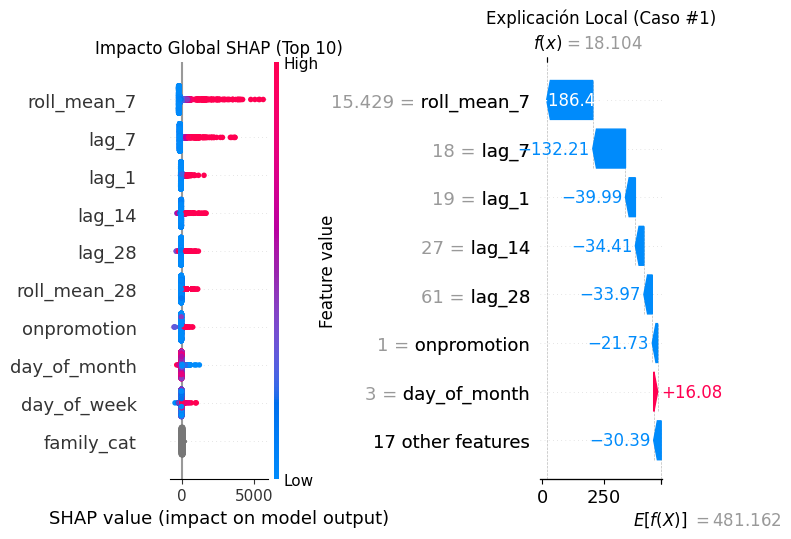


=== RESUMEN EJECUTIVO & IMPACTO ECONÓMICO (15 DÍAS) ===
- Mejor modelo (WAPE): LightGBM (Optuna) (14.94%)
- Cobertura real intervalo [P10 - P90]: 78.60%
- Reducción de quiebres de stock: -4939.6% (609 -> 30,691 uds)
- Variación capital inmovilizado diario: $20,307,862.26 ($36,225,941.41 -> $15,918,079.15)
- Margen bruto rescatado estimado (15d): $0.00


In [12]:
# 1. SHAP Global y Local (sobre muestra representativa de test)
X_sample = test_df[features].sample(n=3000, random_state=42).reset_index(drop=True)
explainer = shap.TreeExplainer(model_lgb_opt)
shap_values = explainer(X_sample)

# Importancia media absoluta (SHAP)
shap_imp = pd.DataFrame({
    'Variable': features,
    'SHAP_Importancia': np.abs(shap_values.values).mean(axis=0)
}).sort_values('SHAP_Importancia', ascending=False)

print("=== TOP 10 VARIABLES POR IMPACTO SHAP ===")
print(shap_imp.head(10).round(2).to_string(index=False))

# Gráficos SHAP: Beeswarm (Global) y Waterfall (Predicción individual)
fig_shap, axes = plt.subplots(1, 2, figsize=(15, 5))
plt.sca(axes[0])
shap.summary_plot(shap_values, X_sample, max_display=10, show=False)
axes[0].set_title('Impacto Global SHAP (Top 10)')

plt.sca(axes[1])
shap.plots.waterfall(shap_values[0], max_display=8, show=False)
axes[1].set_title('Explicación Local (Caso #1)')
plt.tight_layout()
plt.show()

# 2. Resumen Ejecutivo de Impacto Económico Simulado (15 días)
quiebres_est = comparativa_pol.loc[0, 'Unidades_Quiebre']
quiebres_ml = comparativa_pol.loc[1, 'Unidades_Quiebre']
cap_est = comparativa_pol.loc[0, 'Capital_Prom_Diario ($)']
cap_ml = comparativa_pol.loc[1, 'Capital_Prom_Diario ($)']

reduccion_quiebres_pct = (quiebres_est - quiebres_ml) / (quiebres_est + 1e-8) * 100
ahorro_capital = cap_est - cap_ml
margen_promedio_estimado = 2.20
ventas_rescatadas_usd = max(0, quiebres_est - quiebres_ml) * margen_promedio_estimado

print("\n=== RESUMEN EJECUTIVO & IMPACTO ECONÓMICO (15 DÍAS) ===")
print(f"- Mejor modelo (WAPE): {df_resultados.iloc[0]['Modelo']} ({df_resultados.iloc[0]['WAPE (%)']}%)")
print(f"- Cobertura real intervalo [P10 - P90]: {cobertura:.2f}%")
print(f"- Reducción de quiebres de stock: {reduccion_quiebres_pct:.1f}% ({quiebres_est:,.0f} -> {quiebres_ml:,.0f} uds)")
print(f"- Variación capital inmovilizado diario: ${ahorro_capital:,.2f} (${cap_est:,.2f} -> ${cap_ml:,.2f})")
print(f"- Margen bruto rescatado estimado (15d): ${ventas_rescatadas_usd:,.2f}")

In [13]:
import os
os.makedirs('/content/github_export/outputs', exist_ok=True)
os.makedirs('/content/github_export/images', exist_ok=True)

# Exportar tablas resumen
df_resultados.to_csv('/content/github_export/outputs/model_benchmark.csv', index=False)
inv_base.round(2).to_csv('/content/github_export/outputs/inventory_recommendations.csv', index=False)
shap_imp.round(4).to_csv('/content/github_export/outputs/shap_feature_importance.csv', index=False)
test_df[['date', 'store_nbr', 'family', 'sales', 'P10', 'P50', 'P90']].head(5000).round(2).to_csv(
    '/content/github_export/outputs/probabilistic_forecasts_sample.csv', index=False
)

# Guardar gráfico SHAP
fig_shap.savefig('/content/github_export/images/shap_explainability.png', dpi=300, bbox_inches='tight')

# Generar requirements.txt
with open('/content/github_export/requirements.txt', 'w') as f:
    f.write("polars\npandas\nnumpy\nscipy\nstatsmodels\nstatsforecast\nscikit-learn\nlightgbm\nxgboost\noptuna\nshap\nplotly\nmatplotlib\n")

# Comprimir para descarga directa
!zip -r /content/github_export.zip /content/github_export
from google.colab import files
files.download('/content/github_export.zip')

  adding: content/github_export/ (stored 0%)
  adding: content/github_export/requirements.txt (deflated 25%)
  adding: content/github_export/outputs/ (stored 0%)
  adding: content/github_export/outputs/inventory_recommendations.csv (deflated 70%)
  adding: content/github_export/outputs/shap_feature_importance.csv (deflated 36%)
  adding: content/github_export/outputs/probabilistic_forecasts_sample.csv (deflated 72%)
  adding: content/github_export/outputs/model_benchmark.csv (deflated 31%)
  adding: content/github_export/images/ (stored 0%)
  adding: content/github_export/images/shap_explainability.png (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>